# Customer Churn Prediction

## Project Overview

This notebook builds a binary classification model to predict whether a telecom customer will churn.

### Workflow

1. Load and understand the dataset
2. Perform exploratory data analysis (EDA)
3. Prepare the data
4. Split data into training and test sets
5. Build leakage-free preprocessing pipelines
6. Train KNN and Gaussian Naive Bayes models
7. Evaluate both models using multiple metrics
8. Compare the models
9. Draw a concise conclusion and identify next improvements

> **Important:** preprocessing parameters such as the median imputer, encoder, and scaler are learned from the training data only. This prevents test-set leakage.

## 1. Import Libraries

Keep imports grouped by purpose so the notebook is easy to maintain.

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Data preparation
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Train / test split
from sklearn.model_selection import train_test_split, GridSearchCV

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)

## 2. Load the Dataset

The original notebook used the Telco Customer Churn dataset in Google Colab. Keep the same dataset path when using this notebook in Colab.

If you are running locally, change `DATA_PATH` to the location of your CSV file.

In [2]:
DATA_PATH = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the Dataset

Start with the basic structure before making modeling decisions.

In [3]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.shape

Rows: 7043
Columns: 21


(7043, 21)

In [4]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isna().sum().sort_values(ascending=False).head(10)

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Initial Data Quality Check

`TotalCharges` is stored as text in this dataset. Convert it to numeric so it can be used as a numerical feature.

Blank values become `NaN` and will be handled later by the preprocessing pipeline.

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after TotalCharges conversion:")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values after TotalCharges conversion:
TotalCharges    11
dtype: int64


## 5. Exploratory Data Analysis

EDA is used to understand the target distribution, feature patterns, and possible relationships with churn. The following analysis is descriptive; model preprocessing is handled separately to avoid leakage.

### 5.1 Churn Distribution

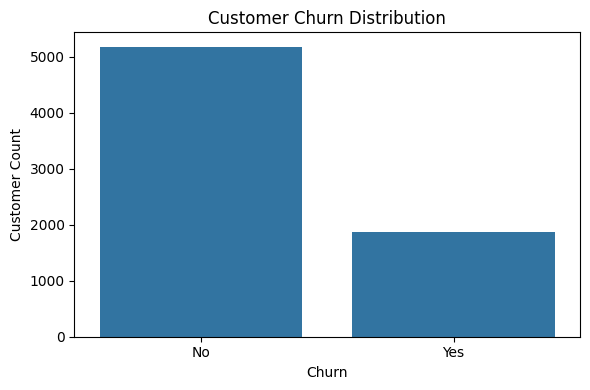

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Proportion:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

print(df["Churn"].value_counts())
print("\nProportion:")
print(df["Churn"].value_counts(normalize=True).round(3))

### 5.2 Categorical Features vs Churn

These plots help identify categorical variables that may show different churn patterns across groups.

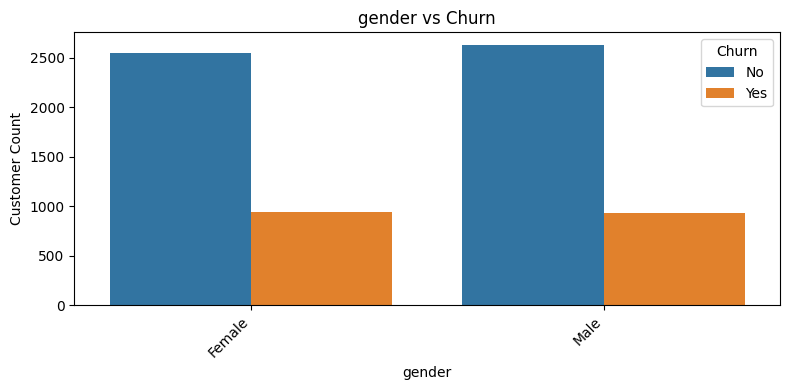

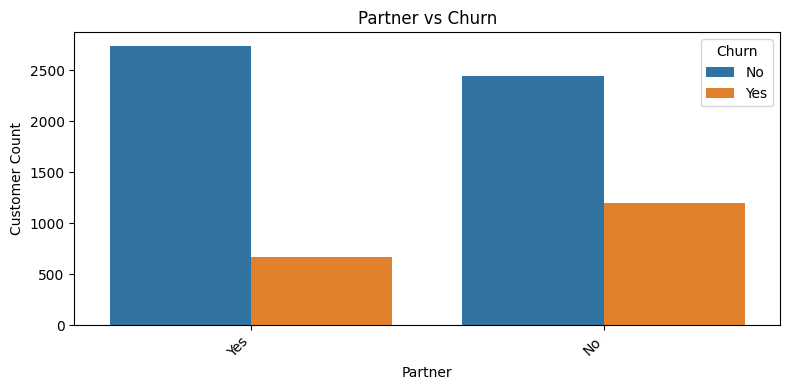

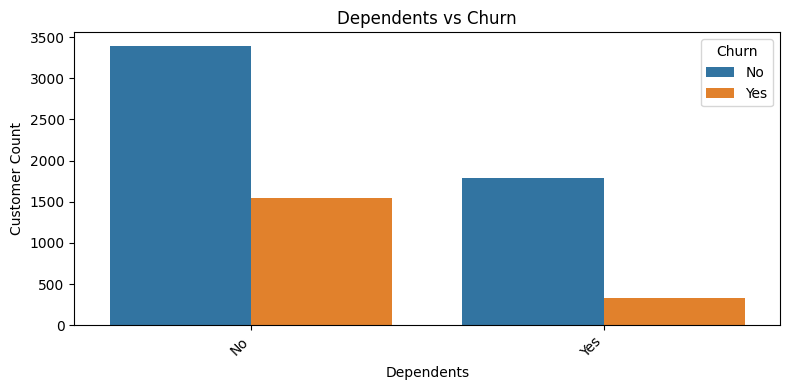

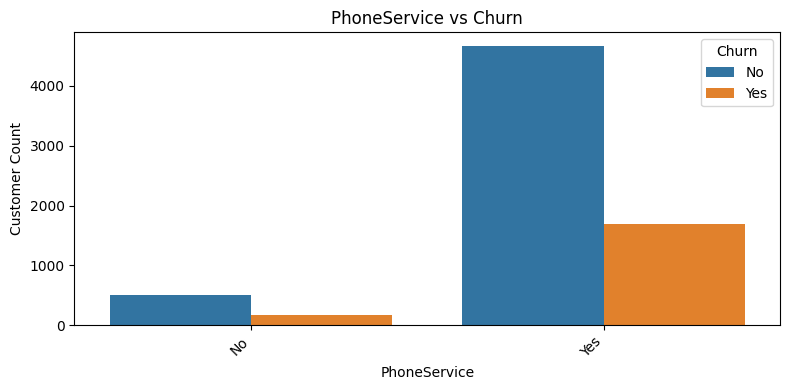

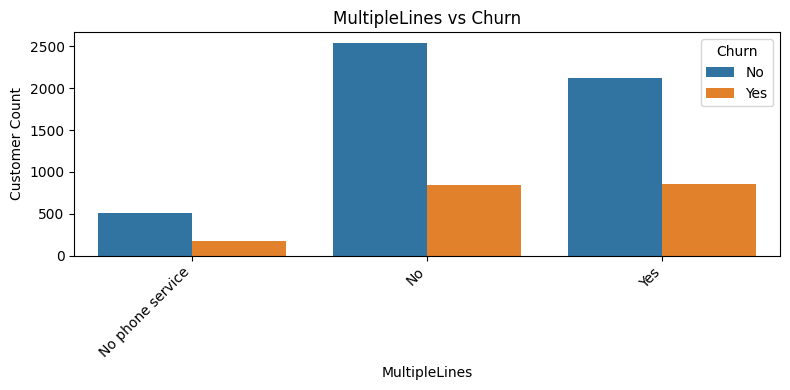

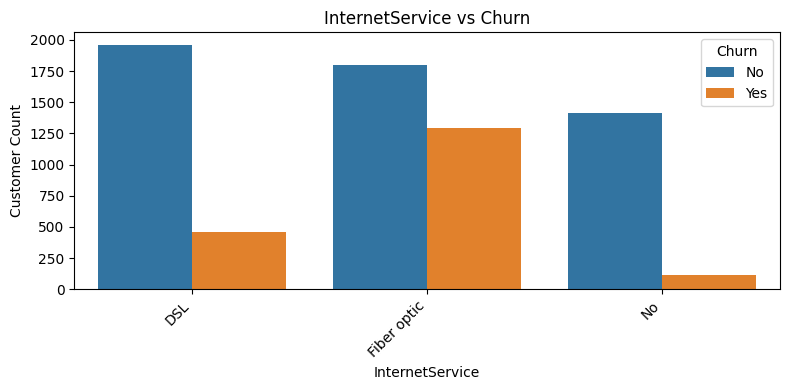

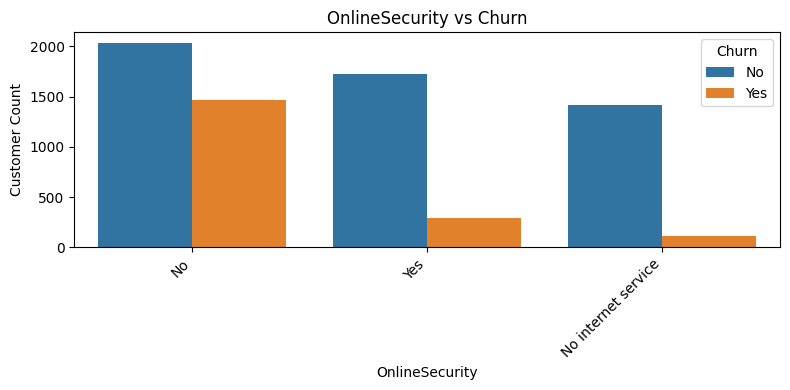

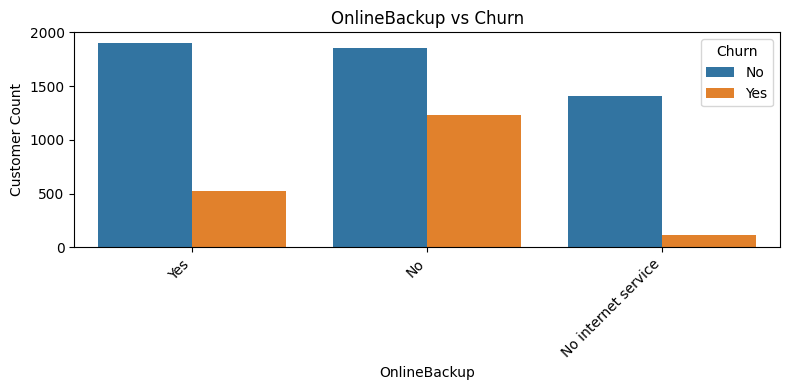

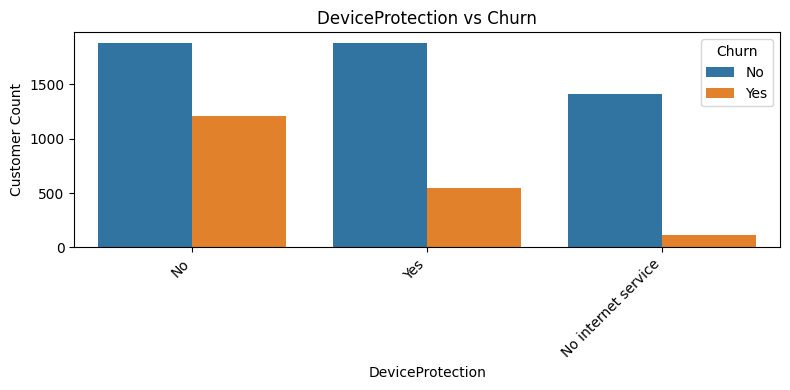

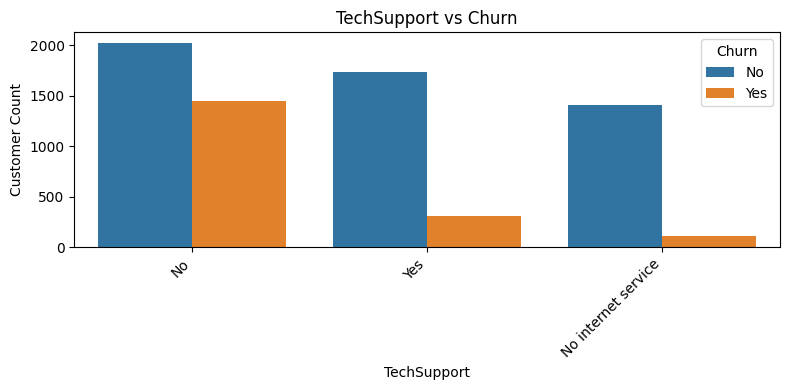

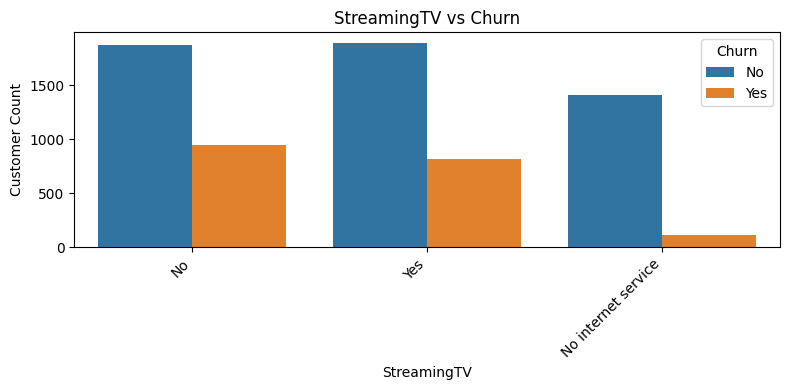

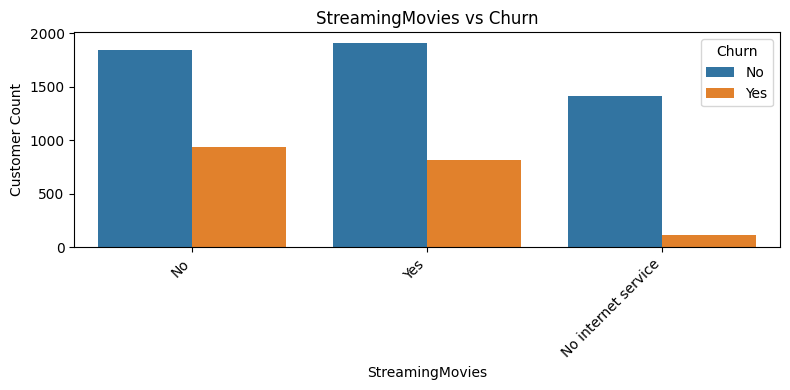

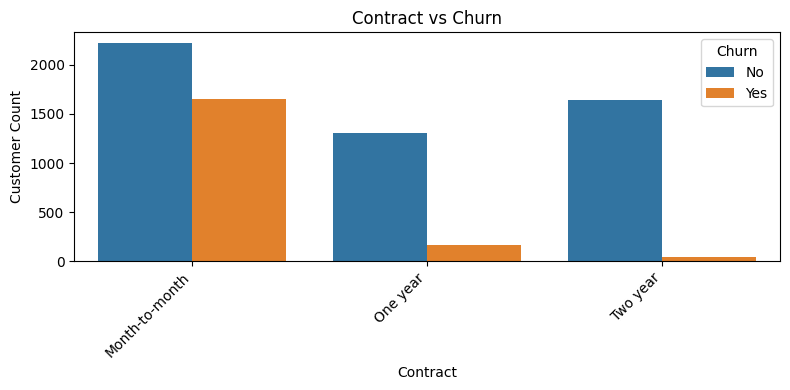

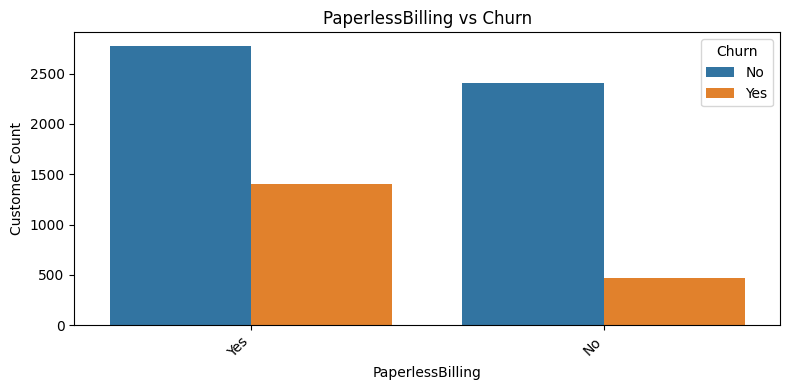

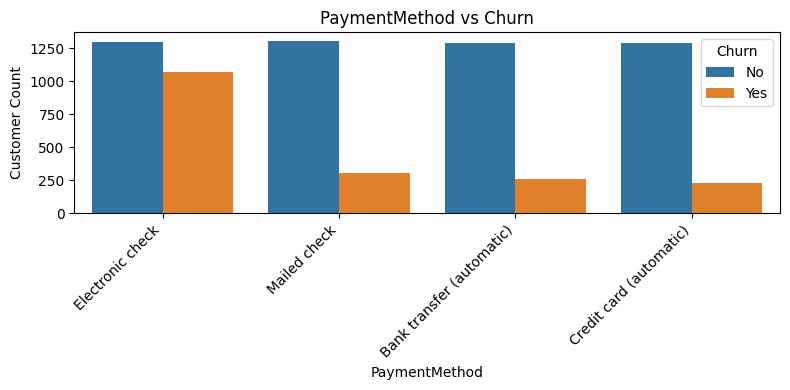

In [10]:
categorical_features_eda = df.select_dtypes(include="object").columns.tolist()
categorical_features_eda.remove("customerID")
categorical_features_eda.remove("Churn")

for feature in categorical_features_eda:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=feature, hue="Churn")
    plt.title(f"{feature} vs Churn")
    plt.xlabel(feature)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 5.3 Numerical Features vs Churn

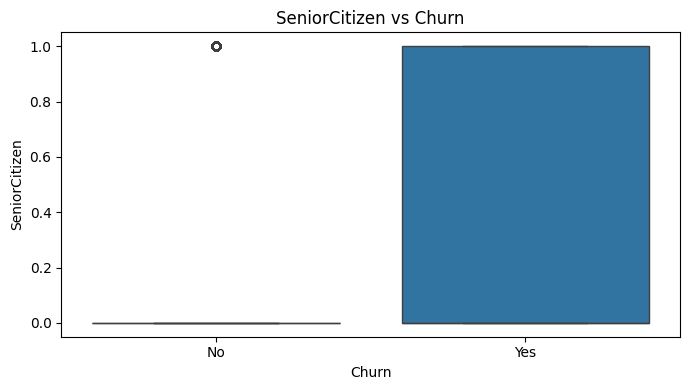

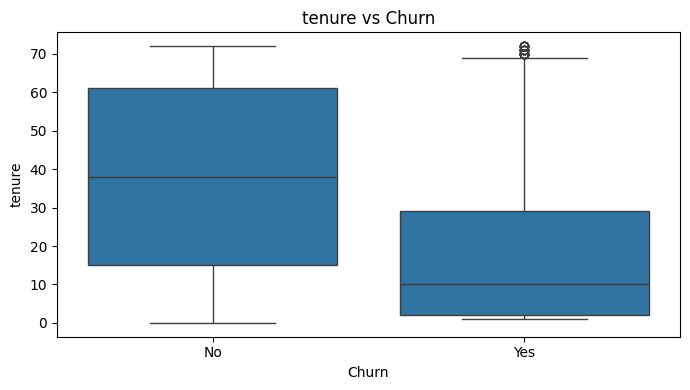

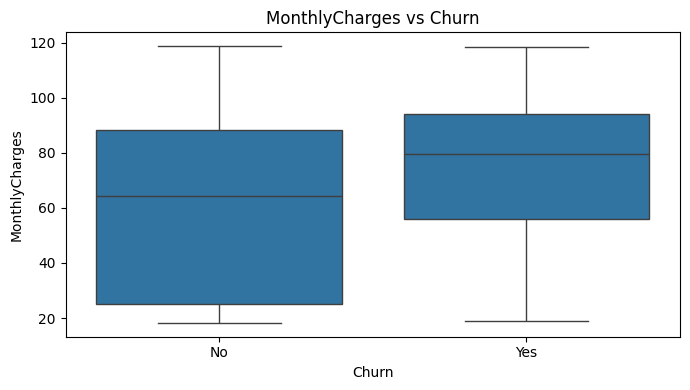

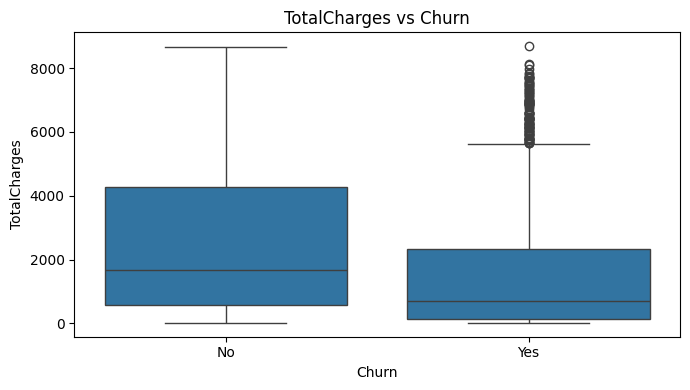

In [11]:
numerical_features_eda = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

for feature in numerical_features_eda:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y=feature)
    plt.title(f"{feature} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

### 5.4 Correlation of Numerical Features

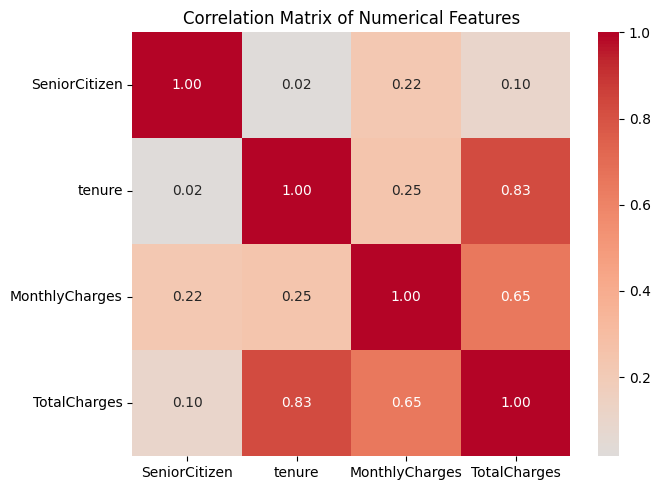

In [12]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[numerical_features_eda].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## 6. Prepare Features and Target

Remove `customerID` because it is an identifier rather than a meaningful predictive feature.

Convert the binary target from `Yes/No` into `1/0` so that the positive class (`1`) represents churn.

In [13]:
model_df = df.drop(columns=["customerID"]).copy()
model_df["Churn"] = model_df["Churn"].map({"No": 0, "Yes": 1}).astype("int64")

X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


## 7. Train-Test Split

Split the data **before** fitting any data-dependent preprocessing.

`stratify=y` keeps the churn/non-churn proportion approximately consistent between training and test sets.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (4930, 19)
Test set: (2113, 19)


## 8. Build the Preprocessing Pipeline

### Numerical features

- Median imputation for missing values
- Standard scaling for distance-based KNN

### Categorical features

- Most-frequent imputation
- One-hot encoding

Using `OneHotEncoder` is preferable to assigning arbitrary numbers to nominal categories because those numbers would create artificial distances for KNN.

Most importantly, the preprocessing is inside a `Pipeline`, so it is fitted only on the training data when the model is trained.

In [15]:
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [16]:
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

## 9. Baseline Models

Two algorithms from the original notebook are retained:

- **K-Nearest Neighbors (KNN)**
- **Gaussian Naive Bayes**

The preprocessing is attached to each model so the complete training process is reproducible and leakage-free.

In [17]:
knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier()),
    ]
)

gnb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GaussianNB()),
    ]
)

## 10. Train the Baseline Models

In [18]:
knn_pipeline.fit(X_train, y_train)
gnb_pipeline.fit(X_train, y_train)

print("Baseline models trained successfully.")

Baseline models trained successfully.


## 11. Generate Predictions

In [19]:
y_pred_knn = knn_pipeline.predict(X_test)
y_pred_gnb = gnb_pipeline.predict(X_test)

print("First 10 KNN predictions:", y_pred_knn[:10])
print("First 10 Gaussian NB predictions:", y_pred_gnb[:10])

First 10 KNN predictions: [1 0 1 0 0 0 0 0 0 0]
First 10 Gaussian NB predictions: [1 0 1 0 0 0 0 0 0 0]


## 12. Model Evaluation

Use the correct metric convention:

```python
classification_report(y_true, y_pred)
```

Here:

- `y_test` = actual labels
- `y_pred` = model predictions

### 12.1 KNN Evaluation

In [20]:
print("KNN Classification Report")
print(classification_report(y_test, y_pred_knn, zero_division=0))
print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_knn, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_knn, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_knn, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, knn_pipeline.predict_proba(X_test)[:, 1]):.4f}")

KNN Classification Report
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1552
           1       0.55      0.55      0.55       561

    accuracy                           0.76      2113
   macro avg       0.69      0.69      0.69      2113
weighted avg       0.76      0.76      0.76      2113

Accuracy: 0.7615
Precision: 0.5506
Recall: 0.5526
F1-score: 0.5516
ROC-AUC: 0.7860


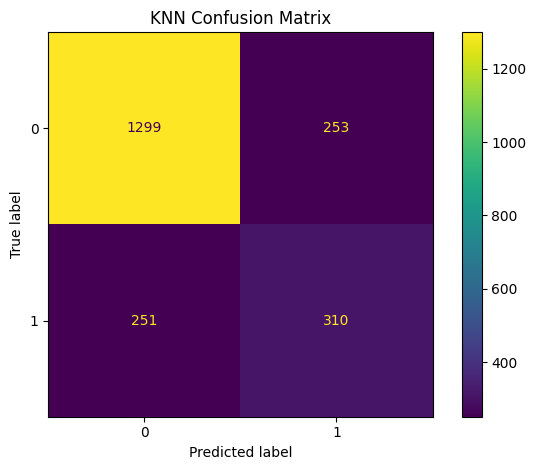

In [21]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn)
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

### 12.2 Gaussian Naive Bayes Evaluation

In [22]:
print("Gaussian Naive Bayes Classification Report")
print(classification_report(y_test, y_pred_gnb, zero_division=0))
print(f"Accuracy: {accuracy_score(y_test, y_pred_gnb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_gnb, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_gnb, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_gnb, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, gnb_pipeline.predict_proba(X_test)[:, 1]):.4f}")

Gaussian Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.92      0.64      0.75      1552
           1       0.46      0.84      0.59       561

    accuracy                           0.69      2113
   macro avg       0.69      0.74      0.67      2113
weighted avg       0.79      0.69      0.71      2113

Accuracy: 0.6914
Precision: 0.4560
Recall: 0.8396
F1-score: 0.5910
ROC-AUC: 0.8074


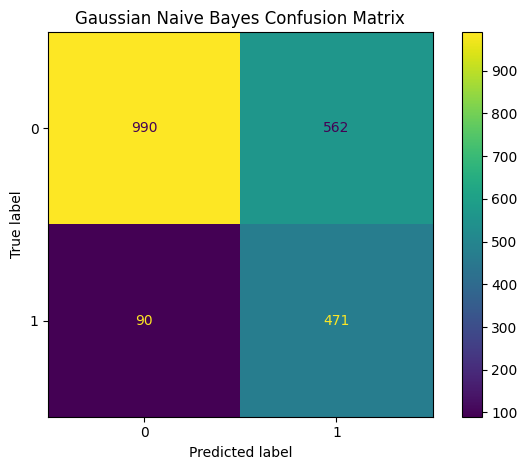

In [23]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gnb)
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

## 13. Compare the Models

Put the main metrics into one table instead of comparing printed outputs manually.

In [24]:
comparison = pd.DataFrame({
    "Model": ["KNN", "Gaussian Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_gnb),
    ],
    "Precision": [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_gnb, zero_division=0),
    ],
    "Recall": [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_gnb, zero_division=0),
    ],
    "F1": [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_gnb, zero_division=0),
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, knn_pipeline.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, gnb_pipeline.predict_proba(X_test)[:, 1]),
    ],
})

comparison.sort_values("F1", ascending=False).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gaussian Naive Bayes,0.691434,0.455954,0.839572,0.590966,0.807372
1,KNN,0.761477,0.550622,0.552585,0.551601,0.785999


## 14. ROC Curve Comparison

<Figure size 700x500 with 0 Axes>

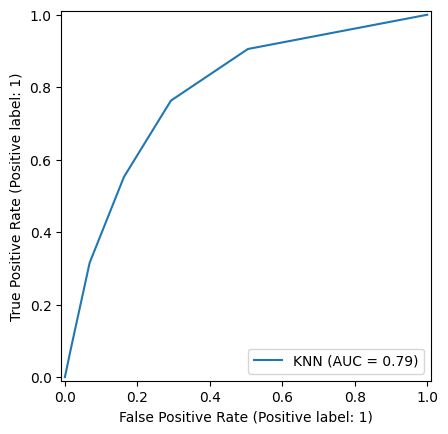

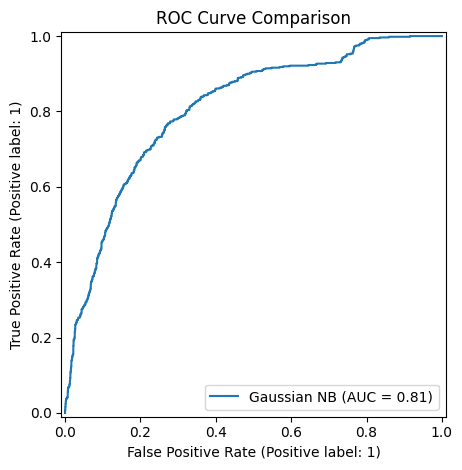

In [25]:
plt.figure(figsize=(7, 5))
RocCurveDisplay.from_estimator(knn_pipeline, X_test, y_test, name="KNN")
RocCurveDisplay.from_estimator(gnb_pipeline, X_test, y_test, name="Gaussian NB")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

## 15. Optional Improvement: Tune KNN

The default KNN model uses a default number of neighbors. Because KNN performance can change with `n_neighbors`, test a small range using cross-validation.

The preprocessing remains inside the pipeline, so each cross-validation fold learns preprocessing only from its training portion.

In [26]:
knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:", knn_grid.best_params_)
print(f"Best cross-validation F1: {knn_grid.best_score_:.4f}")

Best KNN parameters: {'model__n_neighbors': 15, 'model__weights': 'uniform'}
Best cross-validation F1: 0.5772


In [27]:
best_knn = knn_grid.best_estimator_
y_pred_best_knn = best_knn.predict(X_test)

print("Tuned KNN test-set report")
print(classification_report(y_test, y_pred_best_knn, zero_division=0))
print(f"Test accuracy: {accuracy_score(y_test, y_pred_best_knn):.4f}")
print(f"Test F1-score: {f1_score(y_test, y_pred_best_knn, zero_division=0):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, best_knn.predict_proba(X_test)[:, 1]):.4f}")

Tuned KNN test-set report
              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1552
           1       0.57      0.57      0.57       561

    accuracy                           0.77      2113
   macro avg       0.71      0.71      0.71      2113
weighted avg       0.77      0.77      0.77      2113

Test accuracy: 0.7738
Test F1-score: 0.5717
Test ROC-AUC: 0.8195


In [28]:
tuned_knn_metrics = pd.DataFrame({
    "Model": ["KNN Baseline", "KNN Tuned"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_best_knn),
    ],
    "Precision": [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_best_knn, zero_division=0),
    ],
    "Recall": [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_best_knn, zero_division=0),
    ],
    "F1": [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_best_knn, zero_division=0),
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, knn_pipeline.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, best_knn.predict_proba(X_test)[:, 1]),
    ],
})

tuned_knn_metrics

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN Baseline,0.761477,0.550622,0.552585,0.551601,0.785999
1,KNN Tuned,0.773781,0.574775,0.568627,0.571685,0.819541


## 16. Final Notes

### What was improved compared with the original notebook

- Standardized notebook headings and spelling
- Removed unused imports and repeated code
- Converted `TotalCharges` before modeling
- Removed `customerID` explicitly
- Split the data **before** fitting preprocessing
- Replaced manual label encoding of categorical features with one-hot encoding
- Used `Pipeline` and `ColumnTransformer` for reproducible preprocessing
- Used `stratify=y` in the train/test split
- Corrected `classification_report(y_test, y_pred)`
- Added precision, recall, F1-score, ROC-AUC, and confusion matrices
- Added a model-comparison table
- Added optional KNN hyperparameter tuning with cross-validation

## Conclusion

After running all cells, summarize the results using the values produced by the notebook rather than hard-coding an accuracy value.

A good conclusion should answer:

1. How well did the models perform?
2. How do precision, recall, and F1 compare?
3. What does the confusion matrix show about churn predictions?
4. Did KNN tuning improve the baseline result?
5. What would you try next?

### Possible next improvements

- Try additional classification algorithms
- Handle class imbalance explicitly if needed
- Perform feature selection
- Tune more hyperparameters
- Use repeated cross-validation for a more robust estimate
- Track experiments and model versions